# 1.  Installation des dépendances

In [1]:
# ==============================
# INSTALLATION YOLO
# ==============================
!pip install ultralytics --quiet
!pip install opencv-python-headless --quiet

print("Installation terminée ✅")

Installation terminée ✅


# 2. Imports et configuration

In [2]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import torch
import warnings
warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device : {device}")

DATASET_PATH = "/kaggle/input/datasets/imaneougni/dataset-faces-detection"
os.makedirs("/kaggle/working/results_yolo", exist_ok=True)
print(f"Dataset path : {DATASET_PATH}")

Device : cpu
Dataset path : /kaggle/input/datasets/imaneougni/dataset-faces-detection


# 3. Chargement des images

In [3]:
import glob

extensions = ["*.jpg", "*.jpeg", "*.png",
              "*.JPG", "*.JPEG", "*.PNG"]
all_images = []
for ext in extensions:
    all_images.extend(glob.glob(
        os.path.join(DATASET_PATH, "**", ext), recursive=True))
    all_images.extend(glob.glob(
        os.path.join(DATASET_PATH, ext)))

test_paths = sorted(list(set(all_images)))
print(f"Images trouvées : {len(test_paths)}")
for i, p in enumerate(test_paths):
    img = cv2.imread(p)
    h, w = img.shape[:2] if img is not None else (0, 0)
    print(f"  [{i:02d}] {os.path.basename(p):40s} {w}×{h}")

Images trouvées : 15
  [00] Middle_Eastern.JPG                       163×208
  [01] african.JPG                              312×210
  [02] asien.png                                425×232
  [03] caucasien.JPG                            316×213
  [04] cry.JPG                                  247×211
  [05] face_mask.JPG                            374×211
  [06] kids.png                                 226×218
  [07] multifaces.JPG                           279×179
  [08] normale.JPG                              170×188
  [09] old.png                                  417×238
  [10] partially_covered.JPG                    159×208
  [11] sunglasses.JPG                           119×217
  [12] sunlight.JPG                             312×210
  [13] voile.jpg                                230×295
  [14] women.png                                287×234


# 4. Téléchargement des poids YOLO face

In [6]:
# ==============================
# TÉLÉCHARGEMENT POIDS YOLO FACE
# ==============================
import urllib.request

# YOLOv8n-face : modèle nano fine-tuné sur détection de visages
# Plus stable et mieux documenté que YOLOv10-face pour cet usage
YOLO_WEIGHTS = "/kaggle/working/yolov8n-face.pt"

if not os.path.exists(YOLO_WEIGHTS):
    print("Téléchargement des poids yolov8n-face...")
    url = "https://huggingface.co/arnabdhar/YOLOv8-Face-Detection/resolve/main/model.pt"
    urllib.request.urlretrieve(url, YOLO_WEIGHTS)
    print(f"Poids téléchargés → {YOLO_WEIGHTS}")
else:
    print(f"Poids déjà présents → {YOLO_WEIGHTS}")

size_mb = os.path.getsize(YOLO_WEIGHTS) / (1024 * 1024)
print(f"Taille du fichier : {size_mb:.1f} MB")

Poids déjà présents → /kaggle/working/yolov8n-face.pt
Taille du fichier : 6.0 MB


# 5. Initialisation YOLO

In [7]:
# ==============================
# INITIALISATION YOLO FACE
# ==============================
from ultralytics import YOLO

yolo_model = YOLO(YOLO_WEIGHTS)

print("YOLOv8n-face initialisé ✅")
print("Architecture  : YOLOv8 nano fine-tuné sur détection de visages")
print("Paradigme     : Single-shot detector (une seule passe)")
print("NMS           : Non-Maximum Suppression intégrée")
print("Landmarks     : Non fournis nativement")
print("Entrée        : image BGR numpy array")

# Warm-up : premier appel plus lent (chargement GPU)
dummy = np.zeros((112, 112, 3), dtype=np.uint8)
_ = yolo_model(dummy, verbose=False)
print("Warm-up effectué ✅")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
YOLOv8n-face initialisé ✅
Architecture  : YOLOv8 nano fine-tuné sur détection de visages
Paradigme     : Single-shot detector (une seule passe)
NMS           : Non-Maximum Suppression intégrée
Landmarks     : Non fournis nativement
Entrée        : image BGR numpy array
Warm-up effectué ✅


# 6. Fonction de détection YOLO

In [8]:
# ==============================
# FONCTION DE DÉTECTION YOLO FACE
# ==============================

def detect_yolo(image_path, conf_threshold=0.50):
    """
    Détecte les visages avec YOLOv8n-face.

    Paramètres
    ----------
    image_path     : chemin vers l'image
    conf_threshold : seuil de confiance minimum (défaut 0.50)

    Retourne
    --------
    boxes     : liste de [x1, y1, x2, y2]
    scores    : liste de scores de confiance
    time_ms   : temps d'inférence en millisecondes
    n_faces   : nombre de visages détectés
    Note      : landmarks = [] — non fournis par YOLO
    """
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        print(f"  ⚠️  Impossible de lire : {image_path}")
        return [], [], 0.0, 0

    h, w = img_bgr.shape[:2]

    t0      = time.perf_counter()
    results = yolo_model(
        img_bgr,
        conf    = conf_threshold,
        verbose = False,
        device  = device,
    )
    t1         = time.perf_counter()
    elapsed_ms = (t1 - t0) * 1000

    boxes  = []
    scores = []

    for r in results:
        for box in r.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
            x1 = max(0, int(x1));  y1 = max(0, int(y1))
            x2 = min(w, int(x2)); y2 = min(h, int(y2))
            boxes.append([x1, y1, x2, y2])
            scores.append(float(box.conf[0].cpu().numpy()))

    return boxes, scores, elapsed_ms, len(boxes)


# Test rapide
boxes, scores, ms, n = detect_yolo(test_paths[0])
print(f"Test rapide sur {os.path.basename(test_paths[0])} :")
print(f"  Visages détectés : {n}")
print(f"  Temps            : {ms:.1f} ms")
if boxes:
    print(f"  Première bbox    : {boxes[0]}")
    print(f"  Score            : {scores[0]:.3f}")

Test rapide sur Middle_Eastern.JPG :
  Visages détectés : 1
  Temps            : 183.6 ms
  Première bbox    : [29, 48, 122, 175]
  Score            : 0.928


# 7. Détection sur toutes les images

In [9]:
# ==============================
# DÉTECTION SUR TOUTES LES IMAGES
# ==============================
print("=" * 60)
print("  YOLO FACE — DÉTECTION SUR TOUTES LES IMAGES")
print("=" * 60)

results_yolo = []

for path in test_paths:
    boxes, scores, ms, n = detect_yolo(path)

    results_yolo.append({
        "image"    : os.path.basename(path),
        "filepath" : path,
        "n_faces"  : n,
        "time_ms"  : round(ms, 2),
        "boxes"    : boxes,
        "landmarks": [],        # YOLO ne fournit pas de landmarks
        "scores"   : scores,
        "detected" : n > 0,
    })

    status    = "✅" if n > 0 else "❌"
    score_str = f"  conf={scores[0]:.2f}" if scores else ""
    print(f"  {status}  {os.path.basename(path):40s} "
          f"→ {n} visage(s)  |  {ms:.1f} ms{score_str}")

times  = [r["time_ms"] for r in results_yolo]
n_ok   = sum(1 for r in results_yolo if r["detected"])
n_miss = sum(1 for r in results_yolo if not r["detected"])

print(f"\n{'='*60}")
print(f"  RÉSUMÉ YOLO FACE")
print(f"{'='*60}")
print(f"  Images testées       : {len(test_paths)}")
print(f"  Détections réussies  : {n_ok}")
print(f"  Images manquées      : {n_miss}")
print(f"  Temps moyen          : {np.mean(times):.1f} ms")
print(f"  Temps médian         : {np.median(times):.1f} ms")
print(f"  Temps min / max      : {np.min(times):.1f} / {np.max(times):.1f} ms")
print(f"  FPS estimé           : {round(1000/np.mean(times), 1)}")
print(f"  Landmarks fournis    : Non")

  YOLO FACE — DÉTECTION SUR TOUTES LES IMAGES
  ✅  Middle_Eastern.JPG                       → 1 visage(s)  |  112.6 ms  conf=0.93
  ✅  african.JPG                              → 1 visage(s)  |  112.2 ms  conf=0.94
  ✅  asien.png                                → 7 visage(s)  |  98.3 ms  conf=0.96
  ❌  caucasien.JPG                            → 0 visage(s)  |  103.8 ms
  ✅  cry.JPG                                  → 1 visage(s)  |  143.0 ms  conf=0.85
  ✅  face_mask.JPG                            → 1 visage(s)  |  99.3 ms  conf=0.89
  ✅  kids.png                                 → 3 visage(s)  |  148.7 ms  conf=0.95
  ✅  multifaces.JPG                           → 6 visage(s)  |  111.3 ms  conf=0.91
  ✅  normale.JPG                              → 1 visage(s)  |  155.0 ms  conf=0.94
  ✅  old.png                                  → 1 visage(s)  |  88.6 ms  conf=0.94
  ❌  partially_covered.JPG                    → 0 visage(s)  |  110.7 ms
  ✅  sunglasses.JPG                           → 1 visag

# 8. Visualisation des détections

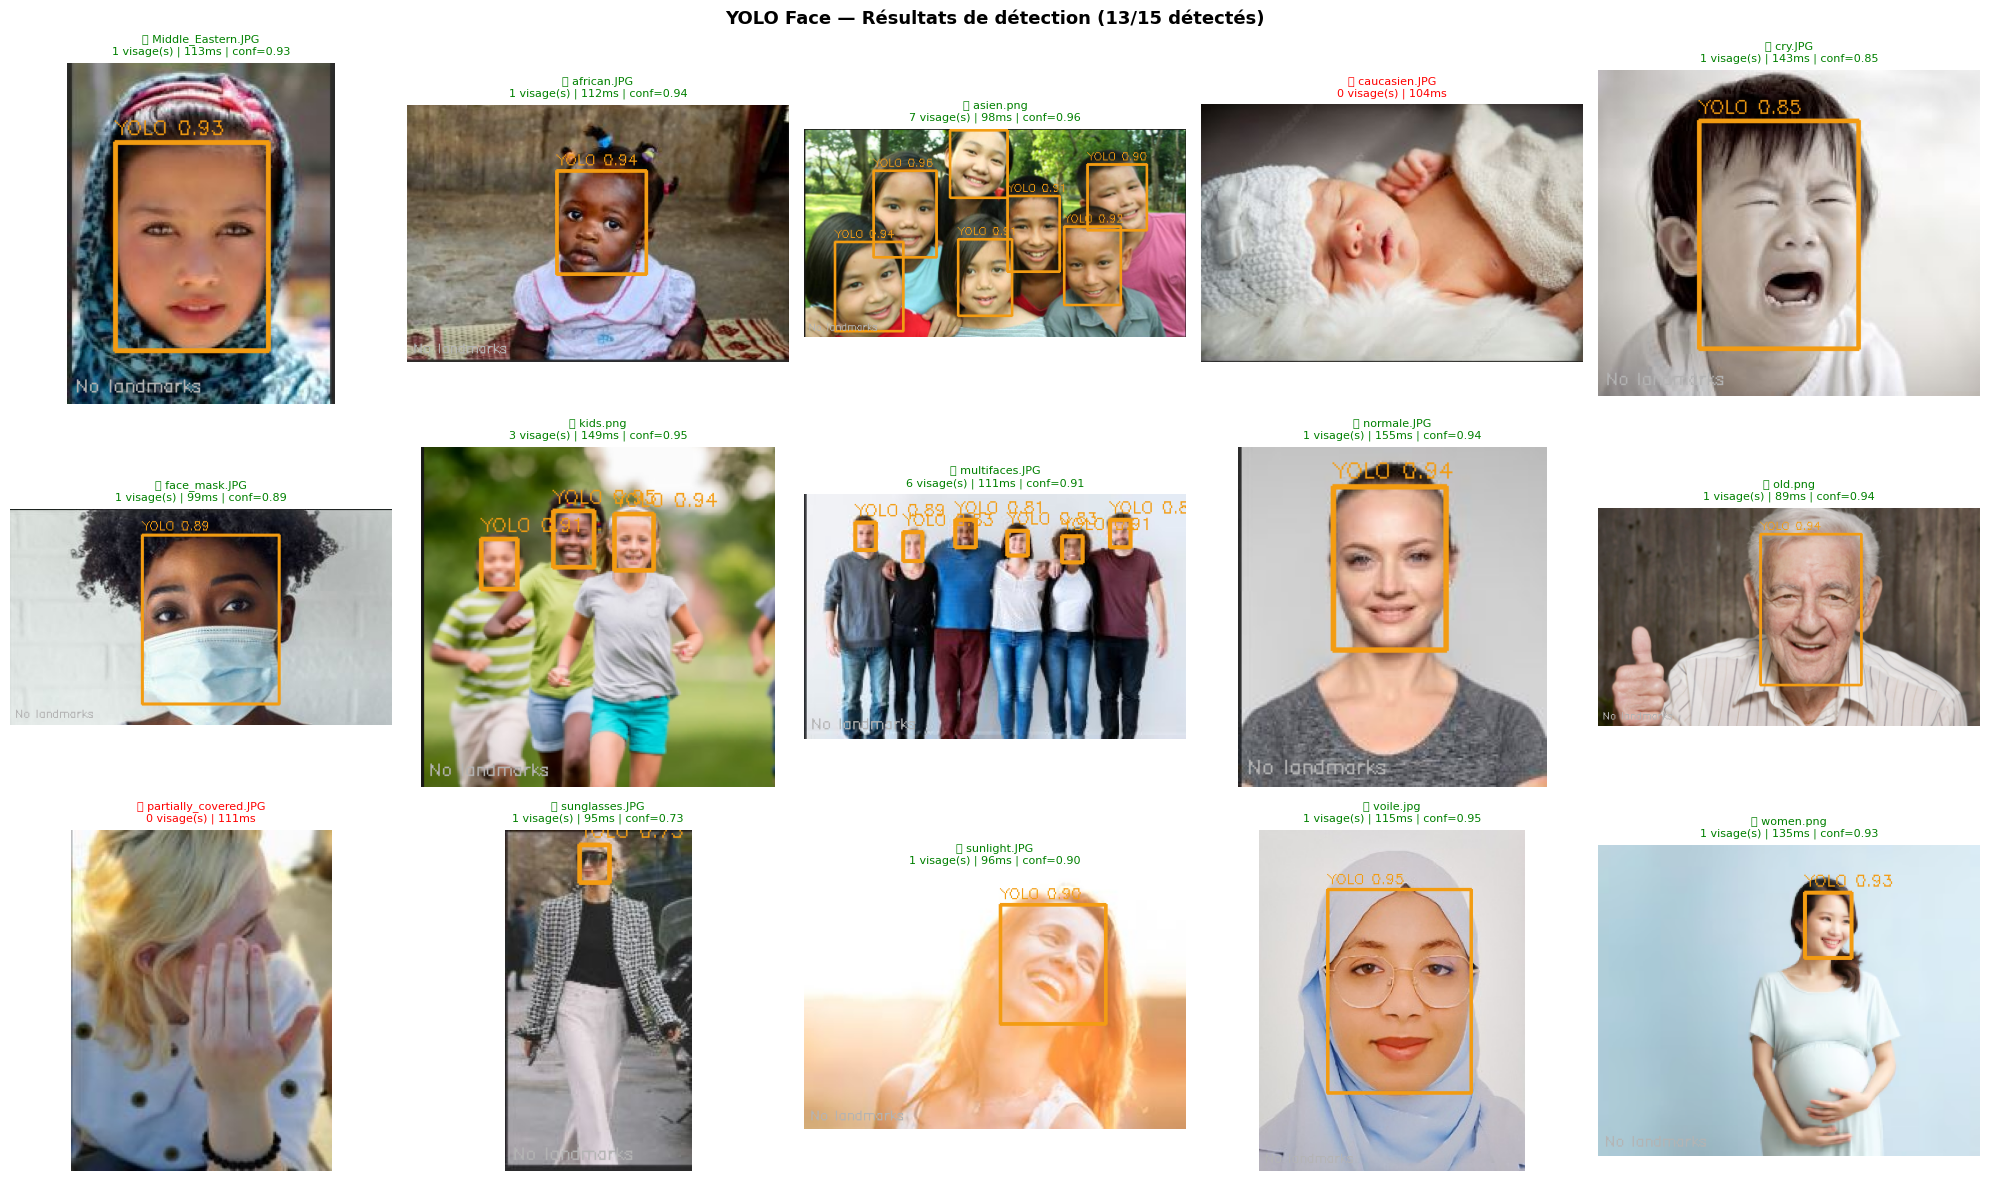

Visualisation sauvegardée ✅


In [10]:
# ==============================
# VISUALISATION DES DÉTECTIONS
# ==============================
COLOR_BOX = (243, 156, 18)   # orange YOLO
COLOR_TXT = (255, 255, 255)  # blanc

def draw_yolo_result(result):
    img = cv2.imread(result["filepath"])
    if img is None:
        return np.zeros((200, 200, 3), dtype=np.uint8)

    img  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    for i, box in enumerate(result["boxes"]):
        x1, y1, x2, y2 = [int(v) for v in box]

        cv2.rectangle(img, (x1, y1), (x2, y2), COLOR_BOX, 2)

        label = "YOLO"
        if i < len(result["scores"]):
            label += f" {result['scores'][i]:.2f}"
        cv2.putText(img, label, (x1, max(y1 - 5, 0)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, COLOR_BOX, 1)

    # Mention explicite : pas de landmarks
    if result["n_faces"] > 0:
        cv2.putText(img, "No landmarks", (5, img.shape[0] - 8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.35, (180, 180, 180), 1)

    return img


n     = len(results_yolo)
n_col = min(5, n)
n_row = (n + n_col - 1) // n_col

fig, axes = plt.subplots(n_row, n_col,
                          figsize=(4 * n_col, 4 * n_row))
fig.suptitle(
    f"YOLO Face — Résultats de détection "
    f"({sum(r['detected'] for r in results_yolo)}/{n} détectés)",
    fontsize=13, fontweight="bold"
)

if n_row == 1 and n_col == 1:
    axes = [[axes]]
elif n_row == 1:
    axes = [list(axes)]
else:
    axes = [list(row) for row in axes]
flat_axes = [ax for row in axes for ax in row]

for i, ax in enumerate(flat_axes):
    if i < len(results_yolo):
        r       = results_yolo[i]
        img_viz = draw_yolo_result(r)
        ax.imshow(img_viz)
        color  = "green" if r["detected"] else "red"
        status = "✅" if r["detected"] else "❌"
        sc_str = (f" | conf={r['scores'][0]:.2f}"
                  if r["scores"] else "")
        ax.set_title(
            f"{status} {r['image']}\n"
            f"{r['n_faces']} visage(s) | {r['time_ms']:.0f}ms{sc_str}",
            fontsize=8, color=color
        )
    ax.axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/results_yolo/01_detections.png",
            dpi=120, bbox_inches="tight")
plt.show()
print("Visualisation sauvegardée ✅")

# 9. Graphiques de performance

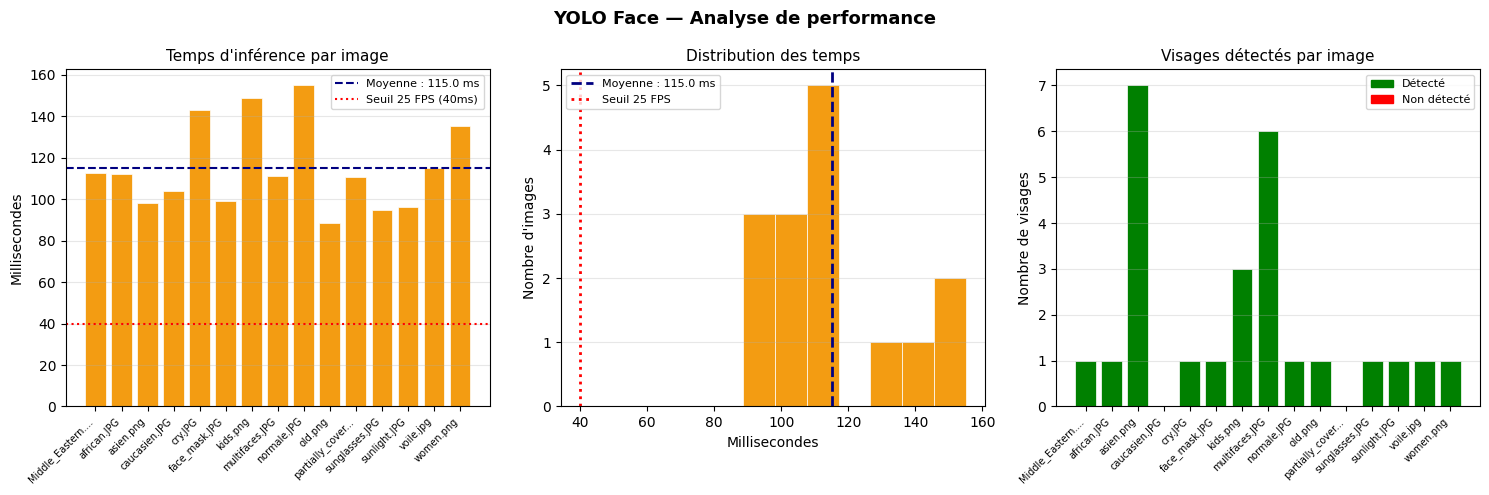

Graphiques sauvegardés ✅


In [11]:
# ==============================
# GRAPHIQUES DE PERFORMANCE
# ==============================
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("YOLO Face — Analyse de performance",
             fontsize=13, fontweight="bold")

COLOR = "#F39C12"

image_names   = [r["image"][:15] + "..."
                 if len(r["image"]) > 15 else r["image"]
                 for r in results_yolo]
times_per_img = [r["time_ms"] for r in results_yolo]

# Temps par image
axes[0].bar(range(len(image_names)), times_per_img,
            color=COLOR, edgecolor="white", linewidth=0.5)
axes[0].axhline(y=np.mean(times_per_img), color="navy",
                linestyle="--", linewidth=1.5,
                label=f"Moyenne : {np.mean(times_per_img):.1f} ms")
axes[0].axhline(y=40, color="red", linestyle=":",
                linewidth=1.5, label="Seuil 25 FPS (40ms)")
axes[0].set_xticks(range(len(image_names)))
axes[0].set_xticklabels(image_names, rotation=45, ha="right", fontsize=7)
axes[0].set_title("Temps d'inférence par image", fontsize=11)
axes[0].set_ylabel("Millisecondes")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.3)

# Distribution des temps
axes[1].hist(times_per_img,
             bins=max(5, len(times_per_img) // 2),
             color=COLOR, edgecolor="white", linewidth=0.5)
axes[1].axvline(x=np.mean(times_per_img), color="navy",
                linestyle="--", linewidth=2,
                label=f"Moyenne : {np.mean(times_per_img):.1f} ms")
axes[1].axvline(x=40, color="red", linestyle=":",
                linewidth=2, label="Seuil 25 FPS")
axes[1].set_title("Distribution des temps", fontsize=11)
axes[1].set_xlabel("Millisecondes")
axes[1].set_ylabel("Nombre d'images")
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.3)

# Visages détectés
n_faces_per_img = [r["n_faces"] for r in results_yolo]
colors_bar = ["green" if n > 0 else "red" for n in n_faces_per_img]
axes[2].bar(range(len(image_names)), n_faces_per_img,
            color=colors_bar, edgecolor="white", linewidth=0.5)
axes[2].set_xticks(range(len(image_names)))
axes[2].set_xticklabels(image_names, rotation=45, ha="right", fontsize=7)
axes[2].set_title("Visages détectés par image", fontsize=11)
axes[2].set_ylabel("Nombre de visages")
axes[2].yaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[2].legend(handles=[
    Patch(color="green", label="Détecté"),
    Patch(color="red",   label="Non détecté")
], fontsize=8)
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/results_yolo/02_performance.png",
            dpi=120, bbox_inches="tight")
plt.show()
print("Graphiques sauvegardés ✅")

# 10.  Sauvegarde des résultats

In [12]:
# ==============================
# SAUVEGARDE DES RÉSULTATS YOLO
# ==============================
df_yolo = pd.DataFrame([{
    "image"      : r["image"],
    "n_faces"    : r["n_faces"],
    "time_ms"    : r["time_ms"],
    "detected"   : r["detected"],
    "fps_eq"     : round(1000 / r["time_ms"], 1) if r["time_ms"] > 0 else 0,
    "mean_score" : round(np.mean(r["scores"]), 3) if r["scores"] else 0,
} for r in results_yolo])

df_yolo.to_csv(
    "/kaggle/working/results_yolo/yolo_results.csv",
    index=False)

times = [r["time_ms"] for r in results_yolo]

summary_yolo = {
    "detecteur"      : "YOLOv8n-face",
    "n_images"       : len(results_yolo),
    "n_detected"     : sum(r["detected"] for r in results_yolo),
    "n_missed"       : sum(not r["detected"] for r in results_yolo),
    "taux_detection" : round(
        sum(r["detected"] for r in results_yolo)
        / len(results_yolo) * 100, 1),
    "time_mean_ms"   : round(np.mean(times), 1),
    "time_median_ms" : round(np.median(times), 1),
    "time_min_ms"    : round(np.min(times), 1),
    "time_max_ms"    : round(np.max(times), 1),
    "fps_estime"     : round(1000 / np.mean(times), 1),
    "landmarks"      : False,
    "n_landmarks"    : 0,
}

print("=" * 60)
print("  RÉSUMÉ FINAL YOLO FACE")
print("=" * 60)
for k, v in summary_yolo.items():
    print(f"  {k:<25} : {v}")

print(f"\nFichiers sauvegardés dans /kaggle/working/results_yolo/")
for f in sorted(os.listdir("/kaggle/working/results_yolo/")):
    print(f"  {f}")

  RÉSUMÉ FINAL YOLO FACE
  detecteur                 : YOLOv8n-face
  n_images                  : 15
  n_detected                : 13
  n_missed                  : 2
  taux_detection            : 86.7
  time_mean_ms              : 115.0
  time_median_ms            : 111.3
  time_min_ms               : 88.6
  time_max_ms               : 155.0
  fps_estime                : 8.7
  landmarks                 : False
  n_landmarks               : 0

Fichiers sauvegardés dans /kaggle/working/results_yolo/
  01_detections.png
  02_performance.png
  yolo_results.csv
